### Steps of analysing a dataset and training a model

1. **data preprocessing** (integration, data cleaning, EDA, feature engineering) and **split** data into train-validation-test

2. **choose a model** (class)/several models (suitable to task, data, ...)

3. pick a grid of hyperparameters and train the model(s) for these hyperparameters on training set (**Hyperparameter tuning**).
Compute the validation error either
     * on the validation set, or
     * via Cross-Validation
to compare intermediate models
$\Rightarrow$ pick the best hyperparameter for the model(s)

4. **retrain the model(s) on all of the training data** (incl. validation set) ($\approx$ 80% of training data, not less)

5. compute the **performance measures on the test set**

6. **pick the overall best model** or if they are too bad, go back to data preprocessing or model selection 

## Example Regression: Predicting Ringsize

(ohne ausführliche gute Doku und Interpretation, nur Kurzfassung zB. nur eine Performance Metrik, kein Feature Selection/Extraction, 
ganz kleiner Beispieldatensatz zur Veranschaulichung des Vorgehens)

In [1]:
import pandas as pd
import numpy as np

### Einlesen & Überblick verschaffen

In [ ]:
# Einlesen
df = pd.read_csv('')


In [3]:
# Beispielzeilen
df.head()

,Weight,Height,Gender,Ringsize
0,51.0,158.9,Female,46.8
1,62.0,156.3,Female,47.1
2,72.0,160.8,Female,49.3
3,77.0,179.6,Female,53.2
4,64.0,156.6,NaN,47.7


In [4]:
# Info Datensatz
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Weight    20 non-null     float64
 1   Height    20 non-null     float64
 2   Gender    20 non-null     object 
 3   Ringsize  21 non-null     float64
dtypes: float64(3), object(1)
memory usage: 800.0+ bytes


In [5]:
# quantitative und kategorielle Features
quant = ['Weight','Height']
cat = ['Gender']

### Data Preprocessing

<center>
<figure>
<img src="data_prep.png" width="800" height="600"> 

</figure>
</center>

### Train-Test-Split

In [1]:
# Aufteilen der Daten in Train und Test:  train-test set 80%-20%
from sklearn.model_selection import train_test_split
train, test = train_test_split(df, random_state=0, train_size=0.8)


ModuleNotFoundError: No module named 'sklearn'

### Data Preprocessing - EDA

<center>
<figure>
<img src="EDA_part1.png" width="800" height="600"> 

</figure>
</center>


In [ ]:
# check dupliactes
train.duplicated().sum()

0

In [3]:
# check missing values 
train.isna().sum()

NameError: name 'train' is not defined

In [ ]:
# feature distribution quantitative variables
train.describe()

,Weight,Height,Ringsize
count,16.000000,15.000000,16.000000
mean,74.125000,171.426667,54.175000
std,13.739845,11.465443,5.892198
min,51.000000,156.600000,46.800000
25%,66.250000,160.800000,48.700000
50%,72.000000,173.000000,54.700000
75%,79.500000,179.300000,58.475000
max,102.000000,191.000000,63.400000


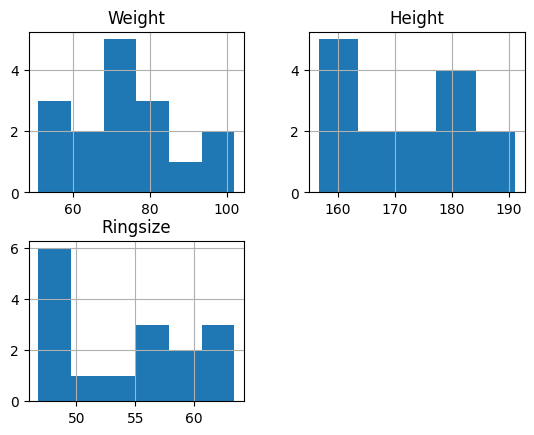

In [ ]:
# histograms
train.hist(bins='rice');

In [ ]:
# feature distribution categorical variables
train[cat].describe()

,Gender
count,15
unique,2
top,Male
freq,8


In [ ]:
# value counts 
train[cat].value_counts()

Gender
Male      8
Female    7
Name: count, dtype: int64

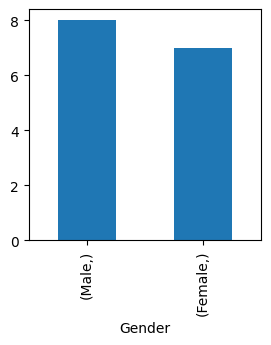

In [ ]:
# bar plots
train[cat].value_counts().plot(kind='bar', figsize=(3,3));

<center>
<figure>
<img src="EDA_part2.png" width="800" height="600"> 

</figure>
</center>


In [ ]:
# correlation coefficient for quantitative correlation
train.corr(method='pearson', numeric_only=True)

,Weight,Height,Ringsize
Weight,1.000000,0.909956,0.877699
Height,0.909956,1.000000,0.950378
Ringsize,0.877699,0.950378,1.000000


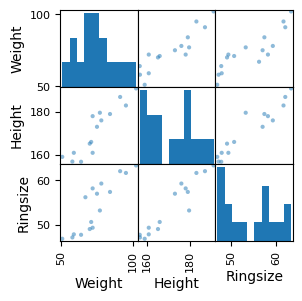

In [ ]:
# scatter plots
from pandas.plotting import scatter_matrix 
scatter_matrix(train, figsize=(3,3));

<Axes: title={'center': 'Ringsize'}, xlabel='Gender'>

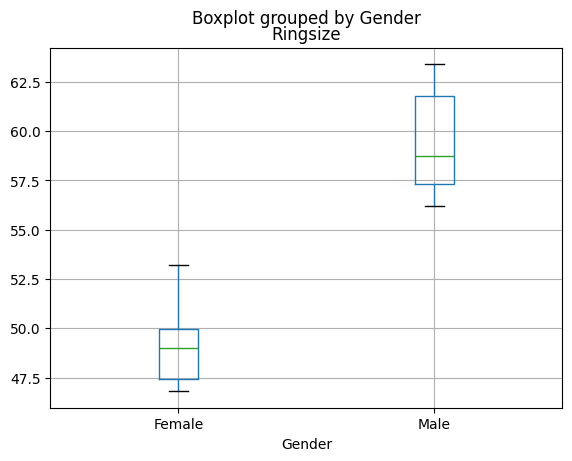

In [ ]:
# Class breakdowns for categorical
train.boxplot(column=['Ringsize'], by='Gender')

### Input-Label Split

In [ ]:
X_train = train.drop(columns=['Ringsize'])
y_train = train['Ringsize']
X_test = test.drop(columns=['Ringsize'])
y_test = test['Ringsize']

### Data Preprocessing - Data Cleaning and Feature Engineering

**Data Cleaning**

- konsistente Formate und Syntax
- Remove Errors and Artifacts
- Find and Remove Outliers
- Handling Missing Values



**Feature Engineering**

- Feature Selection (zB. nutze Erkenntnisse aus EDA, oder teste im Folgenden durch; lassen wir im Beispiel aus)
- Feature Extraction (falls ja, nochmal EDA für die neuen Features v.a. im Bezug zur Outputvariablen)
- Feature Scaling (quantitative Features; abhängig von Modell und Featureverteilung) 
- Encoding Categorical Features (Art abhängig von Feature)
  

**Typische Pipeline - Missing Value Imputation, Encoding, Scaling:**

<center>
<figure>
<img src="transformer.png" width="600" height="600"> 

</figure>
</center>

ggf. müssen manche Features extra behandelt werden

In [ ]:
# define pipeline 
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

quant_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy="median")),
        ('std_scaler', StandardScaler()),
    ])

cat_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy="most_frequent")),
        ('encoder', OneHotEncoder()),
    ])

full_pipeline = ColumnTransformer([
  ("quant", quant_pipeline, quant), 
  ("cat", cat_pipeline, cat),
])



In [ ]:
# fit and transform pipeline (train and test)
X_train = full_pipeline.fit_transform(X_train)
X_test = full_pipeline.transform(X_test) # Achtung Unterschied

### Modelling & Validation

#### 1. Linear Regression

In [ ]:
# import model class
from sklearn.linear_model import LinearRegression

In [ ]:
# define model
model_lg = LinearRegression()

In [ ]:
# check shape of data 
X_train.shape, y_train.shape

((16, 4), (16,))

In [ ]:
# train model
model_lg.fit(X_train, y_train)

LinearRegression()

**Regression Performance Measures:**

$$L_\mathrm{MAE} := \frac{1}{m}\sum^{m}_{i=1} |\mathrm{res}_i|=\frac{1}{m}\sum^{m}_{i=1} |y^{(i)} - \hat{y}^{(i)}|$$ 

$$L_\mathrm{MSE} := \frac{1}{m}\sum^{m}_{i=1} \mathrm{res}_i^2=\frac{1}{m}\sum^{m}_{i=1} (y^{(i)} - \hat{y}^{(i)})^2$$ 

$$R^2:= 1 - \frac{\mathrm{SS_\mathrm{res}}}{\mathrm{SS_\mathrm{tot}}}= 1- \frac{\sum^{m}_{i=1} (y^{(i)} - \hat{y}^{(i)})^2}{\sum^{m}_{i=1} (y^{(i)} - \mu_y)^2}$$

**Overfitting and Underfitting**

Recall: 

<center><figure>
<img src="overfitting.png" width="1200" height="600"> 
<figcaption align = "center"><font size="2">Models with different complexity on training (blue) and unseen test (red) data.</figcaption>
</figure></center>

*  <span style="color:blue">Underfitting:</span> bad performance on training data and validation data
* <span style="color:blue">Overfitting:</span>  good performance on  training data and bad performance on validation data

**Cross Validation**

<center>
<figure>
<img src="cross_validation.png" width="600" height="600"> 
</figure>
</center>

In [ ]:
# cross validation (compare train and validation error to check underfitting/overfitting)
from sklearn.metrics import r2_score
from sklearn.model_selection import cross_validate #(in VL cross_val_score, Vorteil hier Trainingsscore mit ausgebbar)
cross_validate(model_lg, X_train, y_train, scoring='r2', return_train_score=True)

{'fit_time': array([0., 0., 0., 0., 0.]),
 'score_time': array([0.        , 0.00701451, 0.00903511, 0.        , 0.        ]),
 'test_score': array([0.89638621, 0.6939806 , 0.98130054, 0.89380747, 0.99218009]),
 'train_score': array([0.96709177, 0.98805138, 0.95667804, 0.97112552, 0.9493713 ])}

#### 2. KNN mit Hyperparameter K

In [ ]:
# Hyperparameter Tuning mit GridSearchCV

from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV

model_knn= KNeighborsRegressor()
parameter = {'n_neighbors': [1,2,3,4,5]}
grid_search = GridSearchCV(model_knn, parameter, scoring='r2', return_train_score=True, cv=3)
grid_search.fit(X_train, y_train)
pd.DataFrame(grid_search.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,mean_train_score,std_train_score
0,0.000000,0.000000,0.000000,0.000000,1,{'n_neighbors': 1},0.899705,0.962541,0.940446,0.934231,0.026026,1,1.000000,1.000000,1.000000,1.000000,0.000000
1,0.005208,0.007365,0.000000,0.000000,2,{'n_neighbors': 2},0.824754,0.893719,0.821444,0.846639,0.033318,2,0.972437,0.897406,0.965194,0.945012,0.033792
2,0.000000,0.000000,0.005214,0.007374,3,{'n_neighbors': 3},0.644019,0.967483,0.869682,0.827061,0.135449,3,0.993365,0.904312,0.959582,0.952420,0.036707
3,0.007944,0.006452,0.000000,0.000000,4,{'n_neighbors': 4},0.761432,0.826570,0.813423,0.800475,0.028125,4,0.979483,0.787681,0.919077,0.895414,0.080071
4,0.000000,0.000000,0.018906,0.010484,5,{'n_neighbors': 5},0.652436,0.615959,0.752978,0.673791,0.057940,5,0.927026,0.756288,0.910598,0.864637,0.076907


## Finale Evaluation auf der Testset

In [ ]:
# lineare Regression (Trainiere vorher Modell nochmal auf Train + Validation Set falls extra)
r2_score(model_lg.predict(X_test), y_test)

0.9028709148691428

In [ ]:
# bestes KNN (Trainiere vorher Modell nochmal auf Train + Validation Set falls extra)
model_knn = KNeighborsRegressor(n_neighbors=1)
model_knn.fit(X_train, y_train)
r2_score(model_knn.predict(X_test), y_test)

0.7081096241686031